# 03 - Classification: Detecting Off-Spec Hours

The plant mostly cares about one question: **will this hour's concentrate be off-spec?**
We label an hour off-spec (1) when silica > 3.0 %, otherwise on-spec (0), and compare six classifiers:
Logistic Regression, KNN, Naive Bayes, SVM, Decision Tree and Random Forest.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

from src import data
from src.plot_style import setup, save, COLORS
setup()

In [2]:
hourly = data.load_hourly()
train, test = data.time_split(hourly)
X_train, y_train = train[data.FEATURES], train["off_spec"]
X_test, y_test = test[data.FEATURES], test["off_spec"]
print(f"Off-spec share: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

Off-spec share: train 25.3%, test 23.9%


## 1. Choosing the right metric
Only about 25 % of hours are off-spec. A model that always says "on-spec" would already get
about 76 % accuracy and be completely useless. So besides accuracy we look at:

- **Recall** = TP / (TP + FN): of all real off-spec hours, how many did we catch? (most important for the plant)
- **Precision** = TP / (TP + FP): when we raise an alarm, how often is it right?
- **F1** = harmonic mean of precision and recall
- **ROC-AUC**: how well the model ranks off-spec hours above on-spec hours (0.5 = random, 1 = perfect)

To handle the imbalance we use `class_weight="balanced"` where the model supports it, so mistakes on
the smaller class cost more.

In [3]:
print("Accuracy of 'always on-spec':", round(1 - y_test.mean(), 3))

Accuracy of 'always on-spec': 0.761


## 2. Models and hyper-parameter tuning
Each model gets a small grid of hyper-parameters, tuned with 5-fold **time-series** cross-validation
on the training data, scored by F1. Scaling is put inside a pipeline so it is learned only from the
training folds.

In [4]:
tscv = TimeSeriesSplit(n_splits=5)

models = {
    "Logistic Regression": (
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "KNN": (
        make_pipeline(StandardScaler(), KNeighborsClassifier()),
        {"kneighborsclassifier__n_neighbors": [5, 15, 31, 51], "kneighborsclassifier__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        make_pipeline(StandardScaler(), GaussianNB()),
        {"gaussiannb__var_smoothing": [1e-9, 1e-6, 1e-3]}),
    "SVM (RBF kernel)": (
        make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)),
        {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.01]}),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"max_depth": [3, 5, 8], "min_samples_leaf": [10, 30]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42),
        {"max_depth": [5, 10, None], "min_samples_leaf": [5, 20]}),
}

fitted, best_params, rows = {}, {}, {}
for name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=tscv, scoring="f1", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    fitted[name] = best
    best_params[name] = search.best_params_
    pred = best.predict(X_test)
    prob = best.predict_proba(X_test)[:, 1]
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, prob)}
    print(f"{name:20s} best params: {search.best_params_}")

Logistic Regression  best params: {'logisticregression__C': 0.1}


KNN                  best params: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'uniform'}
Naive Bayes          best params: {'gaussiannb__var_smoothing': 1e-09}


SVM (RBF kernel)     best params: {'svc__C': 1, 'svc__gamma': 0.01}


Decision Tree        best params: {'max_depth': 5, 'min_samples_leaf': 30}


Random Forest        best params: {'max_depth': 10, 'min_samples_leaf': 20}


In [5]:
clf_res = pd.DataFrame(rows).T
os.makedirs(data.RES_DIR, exist_ok=True)
clf_res.round(4).to_csv(os.path.join(data.RES_DIR, "classification_results.csv"))
clf_res.round(3).sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.868,0.685,0.830,0.751,0.906
Random Forest,0.863,0.680,0.809,0.739,0.895
Naive Bayes,0.863,0.683,0.799,0.736,0.881
SVM (RBF kernel),0.830,0.604,0.845,0.704,0.894
Decision Tree,0.821,0.592,0.809,0.684,0.874
KNN,0.821,0.735,0.392,0.512,0.790


## 3. Confusion matrices

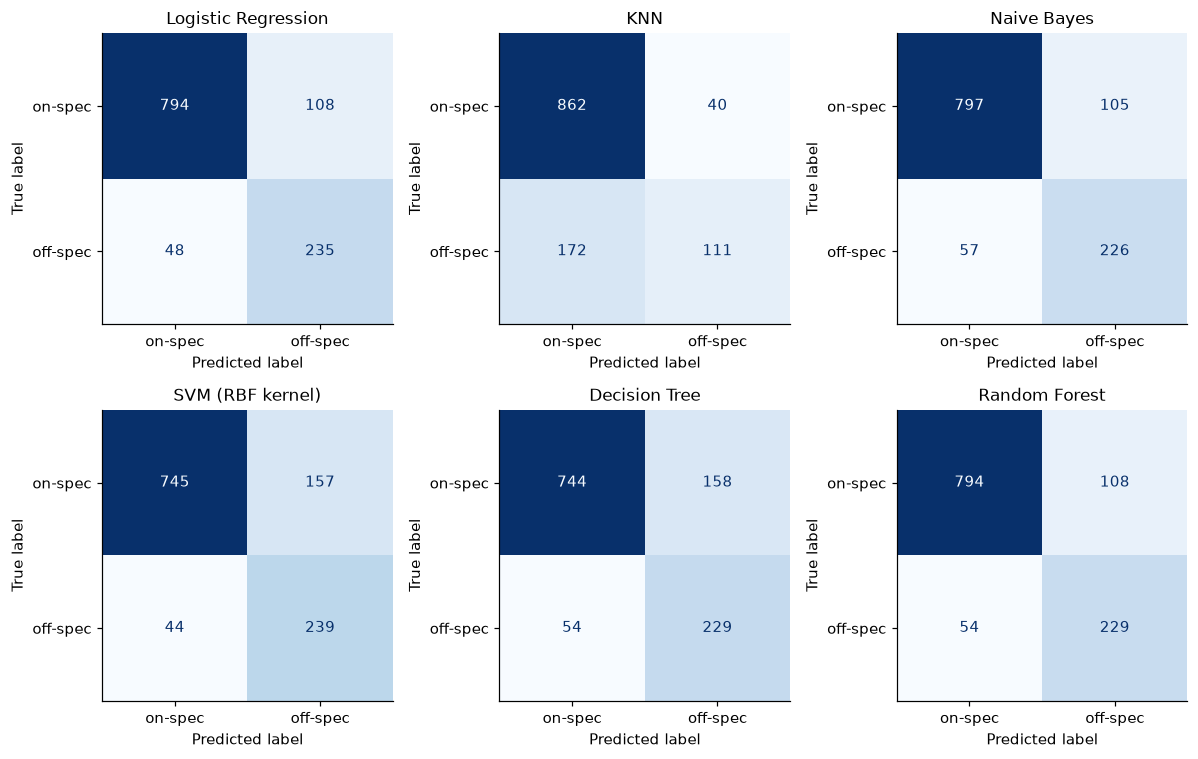

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (name, model) in zip(axes.ravel(), fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["on-spec", "off-spec"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
save(fig, "fig14_confusion_matrices")
plt.show()

## 4. ROC curves

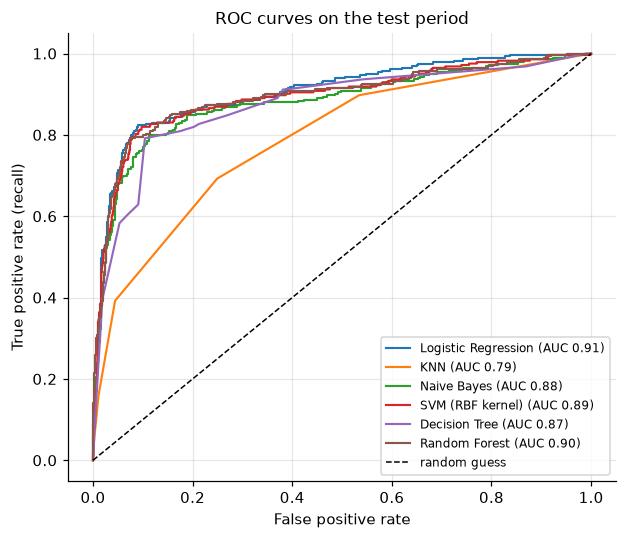

In [7]:
fig, ax = plt.subplots(figsize=(5.8, 5))
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, lw=1.4, label=f"{name} (AUC {rows[name]['ROC-AUC']:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test period")
ax.legend(fontsize=8, loc="lower right")
save(fig, "fig15_roc_curves")
plt.show()

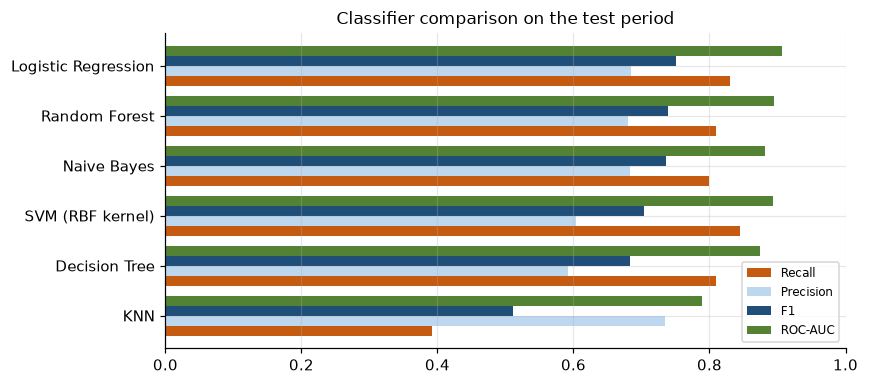

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
clf_res[["Recall", "Precision", "F1", "ROC-AUC"]].sort_values("F1").plot.barh(ax=ax, width=0.8,
        color=[COLORS["accent"], COLORS["light"], COLORS["main"], COLORS["good"]])
ax.set_xlim(0, 1); ax.set_title("Classifier comparison on the test period")
ax.legend(fontsize=8, loc="lower right")
save(fig, "fig16_classifier_comparison")
plt.show()

## 5. Looking inside the models
### 5.1 Logistic regression coefficients
Logistic regression models the log-odds of off-spec as a linear function:
$$\log\frac{p}{1-p} = b_0 + b_1x_1 + \dots + b_{23}x_{23}, \qquad p = \frac{1}{1+e^{-z}}$$
Since the inputs are standardised, exp(b) is the change in the odds for a one-standard-deviation increase.

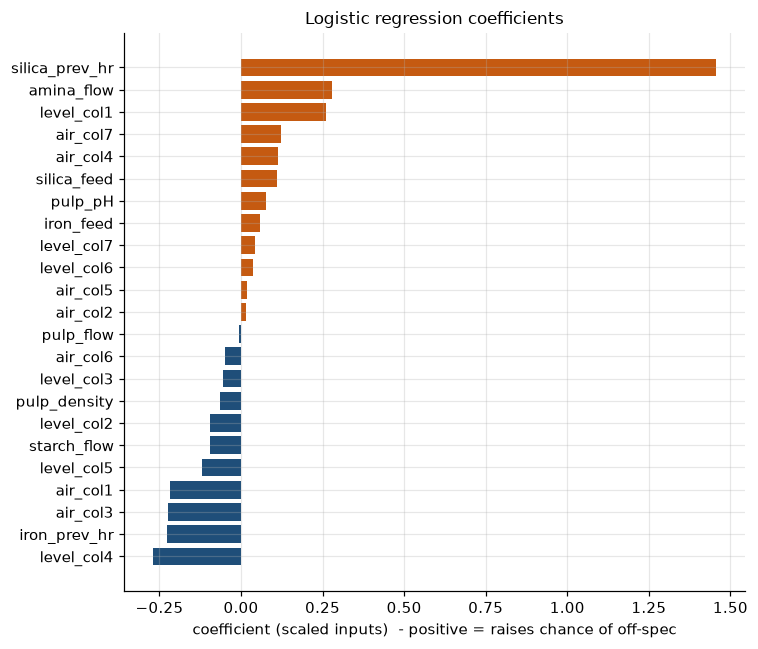

,coef,odds ratio exp(b)
silica_prev_hr,1.457,4.292
amina_flow,0.279,1.322
level_col4,-0.271,0.763
level_col1,0.260,1.297
iron_prev_hr,-0.226,0.798
air_col3,-0.223,0.800
air_col1,-0.219,0.804
air_col7,0.122,1.130


In [9]:
lr = fitted["Logistic Regression"].named_steps["logisticregression"]
lr_coef = pd.Series(lr.coef_[0], index=data.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(lr_coef.index, lr_coef.values, color=[COLORS["accent"] if v > 0 else COLORS["main"] for v in lr_coef.values])
ax.set_xlabel("coefficient (scaled inputs)  - positive = raises chance of off-spec")
ax.set_title("Logistic regression coefficients")
save(fig, "fig17_logistic_coefficients")
plt.show()
pd.DataFrame({"coef": lr_coef, "odds ratio exp(b)": np.exp(lr_coef)}).round(3).sort_values("coef", key=abs, ascending=False).head(8)

### 5.2 A small decision tree (depth 3) to see the rules

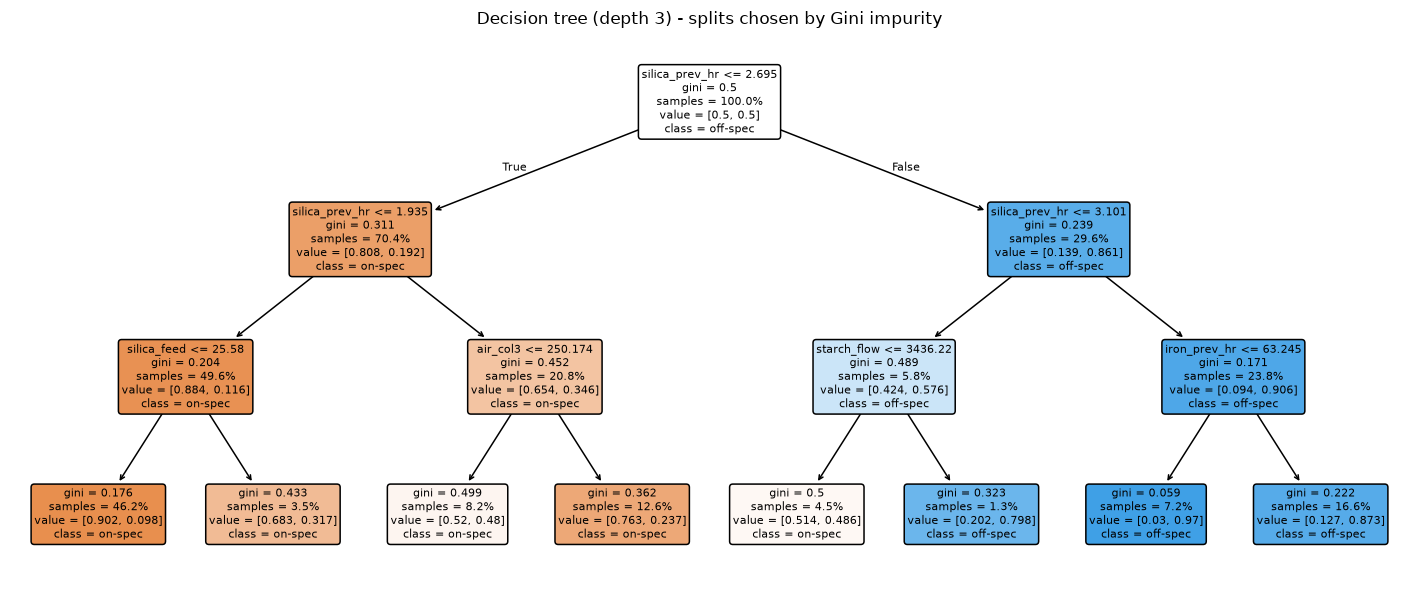

Test F1 of this small tree: 0.755


In [10]:
small_tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(small_tree, feature_names=data.FEATURES, class_names=["on-spec", "off-spec"], filled=True,
          rounded=True, fontsize=7, impurity=True, proportion=True, ax=ax)
ax.set_title("Decision tree (depth 3) - splits chosen by Gini impurity")
save(fig, "fig18_decision_tree")
plt.show()
print("Test F1 of this small tree:", round(f1_score(y_test, small_tree.predict(X_test)), 3))

The first split is on `silica_prev_hr`, as expected. Interestingly this 3-level tree does as well on the
test period as the tuned depth-5 tree, or better. Cross-validation chose depth 5 on the training period, but
the plant behaves a bit differently in the test months and the simpler tree generalises better.

### 5.3 Random forest feature importance

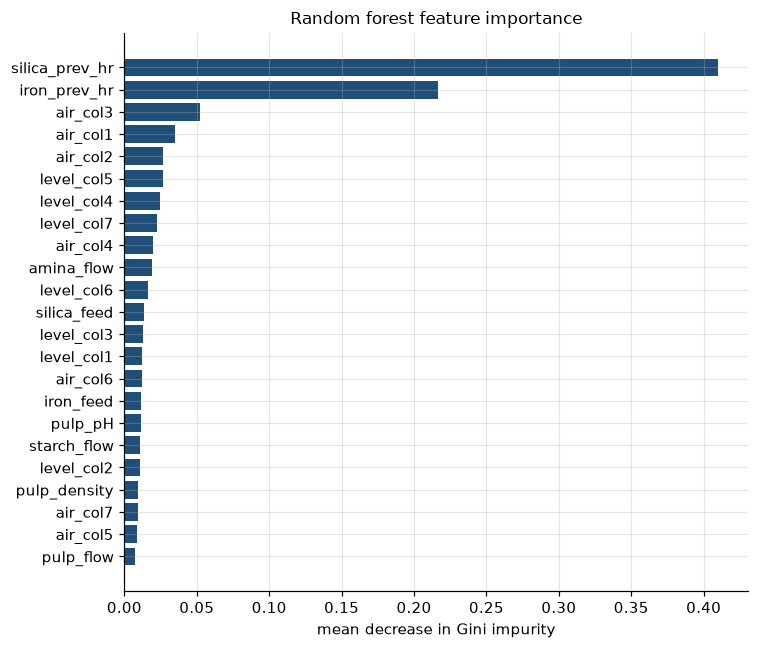

silica_prev_hr    0.410
iron_prev_hr      0.217
air_col3          0.053
air_col1          0.035
air_col2          0.027
level_col5        0.027
level_col4        0.025
level_col7        0.022
dtype: float64

In [11]:
rf = fitted["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=data.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color=COLORS["main"])
ax.set_xlabel("mean decrease in Gini impurity"); ax.set_title("Random forest feature importance")
save(fig, "fig19_rf_importance")
plt.show()
imp.sort_values(ascending=False).round(3).head(8)

## 6. Which inputs matter: sensors, last lab result, or both?
Same six models (same tuned settings) refitted on three input sets.

In [12]:
from sklearn.base import clone
input_sets = {"sensors only": data.PROCESS_VARS, "last lab result only": data.LAB_LAGS, "both (23 inputs)": data.FEATURES}
compare = []
for name, model in fitted.items():
    for set_name, cols in input_sets.items():
        m = clone(model).fit(X_train[cols], y_train)
        compare.append({"model": name, "inputs": set_name,
                        "F1": f1_score(y_test, m.predict(X_test[cols])),
                        "ROC-AUC": roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])})
compare = pd.DataFrame(compare)
compare.round(4).to_csv(os.path.join(data.RES_DIR, "classification_input_sets.csv"), index=False)
compare.pivot(index="model", columns="inputs", values=["F1", "ROC-AUC"]).round(3)

F1                                    \
inputs              both (23 inputs) last lab result only sensors only   
model                                                                    
Decision Tree                  0.684                0.746        0.442   
KNN                            0.512                0.732        0.080   
Logistic Regression            0.751                0.730        0.401   
Naive Bayes                    0.736                0.760        0.277   
Random Forest                  0.739                0.741        0.407   
SVM (RBF kernel)               0.704                0.731        0.414   

                             ROC-AUC                                    
inputs              both (23 inputs) last lab result only sensors only  
model                                                                   
Decision Tree                  0.874                0.887        0.656  
KNN                            0.790                0.861        0.553  
Logistic Regression            0.906                0.906        0.676  
Naive Bayes                    0.881                0.903        0.606  
Random Forest                  0.895                0.900        0.683  
SVM (RBF kernel)               0.894                0.906        0.670

- **Sensors only:** AUC well above 0.5 for most models, so the sensors *do* carry some information
  about off-spec hours - but not enough on their own.
- **Last lab result only:** already strong (AUC about 0.86-0.91), because silica changes slowly.
- **Both:** only logistic regression gains (F1 0.73 -> 0.75). Its L2 penalty (C = 0.1) keeps the
  sensor weights small, so it uses just the useful part of the sensor signal.
- **KNN gets much worse** when the 21 sensors are added (F1 0.73 -> 0.51). KNN treats every input as
  equally important in the distance, so 21 weak, noisy sensor dimensions drown out the 2 informative
  lab values (the "curse of dimensionality"). The other models stay about the same or drop slightly.

## 7. Changing the decision threshold
By default a sample is called off-spec when p > 0.5. The plant may prefer catching more off-spec
hours even if it means more false alarms. For logistic regression:

In [13]:
p = fitted["Logistic Regression"].predict_proba(X_test)[:, 1]
thr_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p > t).astype(int)
    thr_rows.append({"threshold": t, "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
                     "false alarms": int(((pred == 1) & (y_test == 0)).sum()), "missed off-spec hours": int(((pred == 0) & (y_test == 1)).sum())})
thr = pd.DataFrame(thr_rows)
thr.round(3).to_csv(os.path.join(data.RES_DIR, "logistic_threshold.csv"), index=False)
thr.round(3)

,threshold,recall,precision,false alarms,missed off-spec hours
0,0.3,0.873,0.481,267,36
1,0.4,0.845,0.599,160,44
2,0.5,0.830,0.685,108,48
3,0.6,0.792,0.770,67,59
4,0.7,0.710,0.817,45,82


## Conclusions
- All six classifiers clearly beat random guessing. With sensors only, AUC is only about 0.55-0.68;
  with the last lab result it rises to about 0.8-0.9.
- **Logistic regression is the best off-spec detector** (F1 0.75, recall 0.83, AUC 0.91), with Random Forest
  and Naive Bayes close behind. This matches the regression result: the relationship is mostly linear and
  the data is limited, so simple models win.
- The most important inputs are the previous-hour silica and iron, followed by the air flow in
  columns 1-3 (more air -> lower chance of off-spec) and the column levels.
- KNN suffers from the curse of dimensionality when weak sensor inputs are added.
- The threshold lets the plant trade false alarms for missed off-spec hours, depending on what costs more.